In [97]:
from datasets.Harmonized_Datasets import harmonize
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from scipy.stats import ttest_ind, pearsonr
import statsmodels.api as sm


In [7]:
mf_ad = harmonize()['Moffitt']
predictions_df = pd.read_csv("../../outputs/predictions_for_wes_analysis.csv")
cibersort_results = pd.read_csv("../../data/Moffitt/CIBERSORTx/CIBERSORTx_Job16_Results.csv").set_index("Mixture")

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18676


In [93]:
mf_ad.obs

,ABT-199,ExVivo_SampleID,patientID,t11_14,WES_SampleID,Disease_Status
RNA_SampleID,,,,,,
SL414065,68.289579,Pt429,GDH03df143c,NaN,SL409637,ERMM
SL316611,96.238950,Pt227,GDH08065638,0.0,NaN,LRMM
SL399348,65.236880,Pt382,GDH087884bf,0.0,SL393230,ERMM
SL242336,81.704820,Pt166,GDH0bd4be69,1.0,SL241599,LRMM
SL414057,86.576130,Pt419,GDH10e17fff,NaN,SL409628,ERMM
...,...,...,...,...,...,...
SL432596,100.000000,Pt516,GDHea79fae2,NaN,SL434811,ERMM
SL425882,99.259752,Pt478,GDHefa46356,NaN,SL426500,LRMM
SL240795,88.815766,Pt143,GDHf5b6b0bc,0.0,SL241566,ERMM


In [95]:
observations_df = mf_ad.obs.loc[predictions_df['samples']]


In [10]:
true_sensitive_patients = predictions_df[predictions_df['y_true'] == 1]['samples']
true_resistant_patients = predictions_df[predictions_df['y_true'] == 0]['samples']

pred_sensitive_patients = predictions_df[predictions_df['y_pred'] == 1]['samples']
pred_resistant_patients = predictions_df[predictions_df['y_pred'] == 0]['samples']

In [29]:
cibersort_results.columns
cell_types = [c for c in cibersort_results.columns if c != 'P-value' and c != 'Correlation' and c != 'RMSE' and c!= 'Absolute score (sig.score)' ]


In [98]:
cibersort_results_ml = cibersort_results.loc[predictions_df['samples']]
cibersort_results_ml['y_pred'] = list(predictions_df['y_pred'])
cibersort_results_ml['y_true'] = list(predictions_df['y_true'])
cibersort_results_ml['y_prob'] = list(predictions_df['y_prob'])
cibersort_results_ml['ABT-199'] = list(observations_df['ABT-199'])
#cibersort_results.loc[true_sensitive_patients].sort_index()



#### T-test to compare enrichment

In [64]:
# true labels

true_sens_enrichment = cibersort_results_ml.loc[true_sensitive_patients]
true_res_enrichment = cibersort_results_ml.loc[true_resistant_patients]

true_labels_enrichment = {}

for cell_type in cell_types:
    res = ttest_ind(true_sens_enrichment[cell_type], true_res_enrichment[cell_type])
    true_labels_enrichment[cell_type] = {'p': res.pvalue, 'stat': res.statistic}

res_df = pd.DataFrame(true_labels_enrichment).T

res_df['nlog10'] = - np.log10(res_df['p'])
res_df['cell_type'] = res_df.index

In [61]:
res_df[res_df['p'] < 0.05]

,p,stat,nlog10
T cells gamma delta,0.022262,-2.318959,1.652437


In [70]:
-np.log10(0.05)

np.float64(1.3010299956639813)

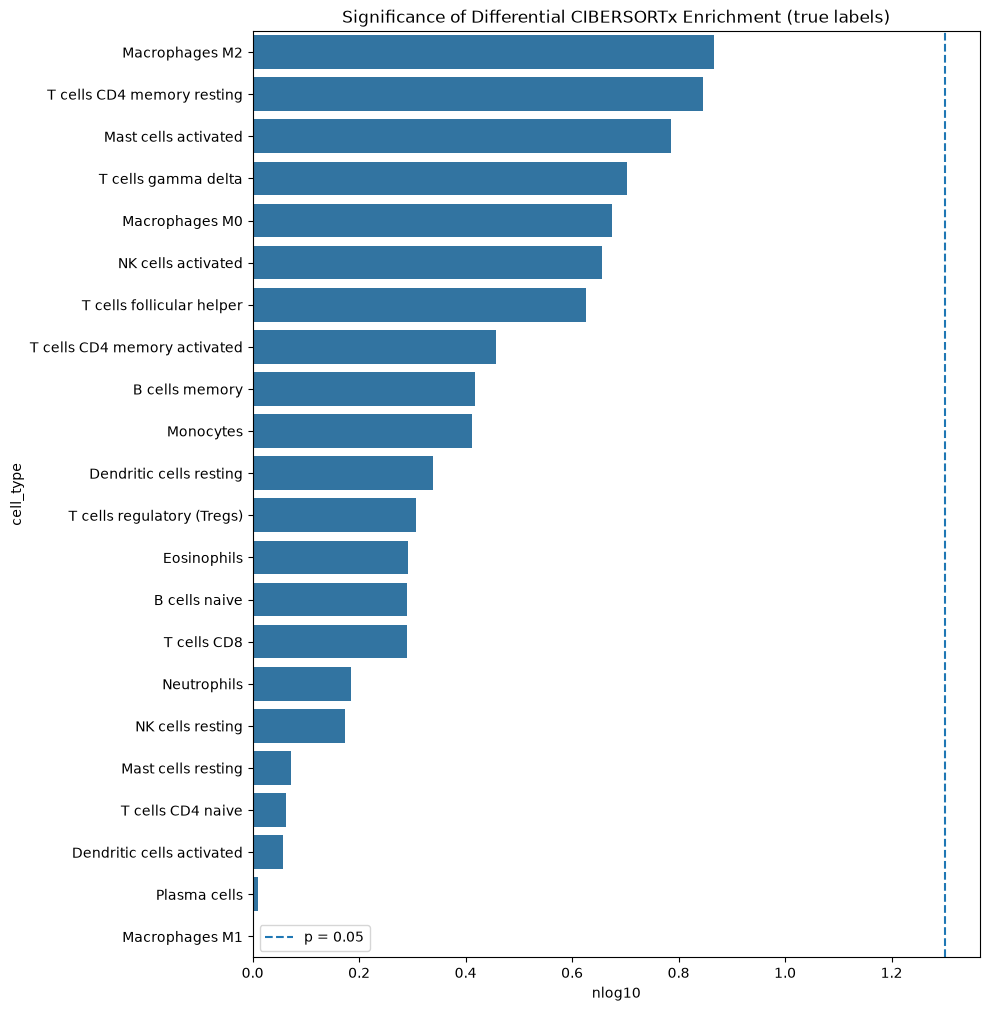

In [322]:
fig, ax = plt.subplots(1, figsize=(10,10))
sns.barplot(res_df.sort_values(by='nlog10', ascending=False), x='nlog10', y='cell_type')

plt.tight_layout()
plt.title("Significance of Differential CIBERSORTx Enrichment (true labels)")
ax.axvline(-np.log10(0.05), ls='--', label='p = 0.05')
#ax.tick_params("x", rotation=90, rotation_mode="xtick")
plt.legend()


Text(0.5, 1.0, 'T cells gamma delta enrichment (CIBERSORTx)')

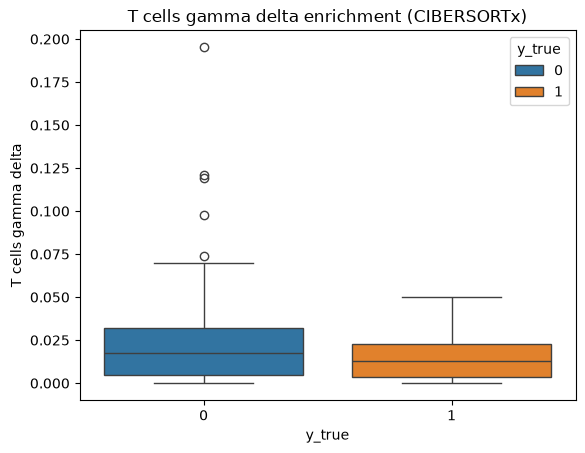

In [325]:
sns.boxplot(cibersort_results_ml, y='T cells gamma delta', x='y_true', hue='y_true')
plt.title('T cells gamma delta enrichment (CIBERSORTx)')

In [90]:
# predicted labels

pred_sens_enrichment = cibersort_results_ml.loc[pred_sensitive_patients]
pred_res_enrichment = cibersort_results_ml.loc[pred_resistant_patients]

pred_labels_enrichment = {}

for cell_type in cell_types:
    res = ttest_ind(pred_sens_enrichment[cell_type], pred_res_enrichment[cell_type])
    pred_labels_enrichment[cell_type] = {'p': res.pvalue, 'stat': res.statistic}

res_df = pd.DataFrame(pred_labels_enrichment).T
res_df['nlog10'] = - np.log10(res_df['p'])
res_df['cell_type'] = res_df.index

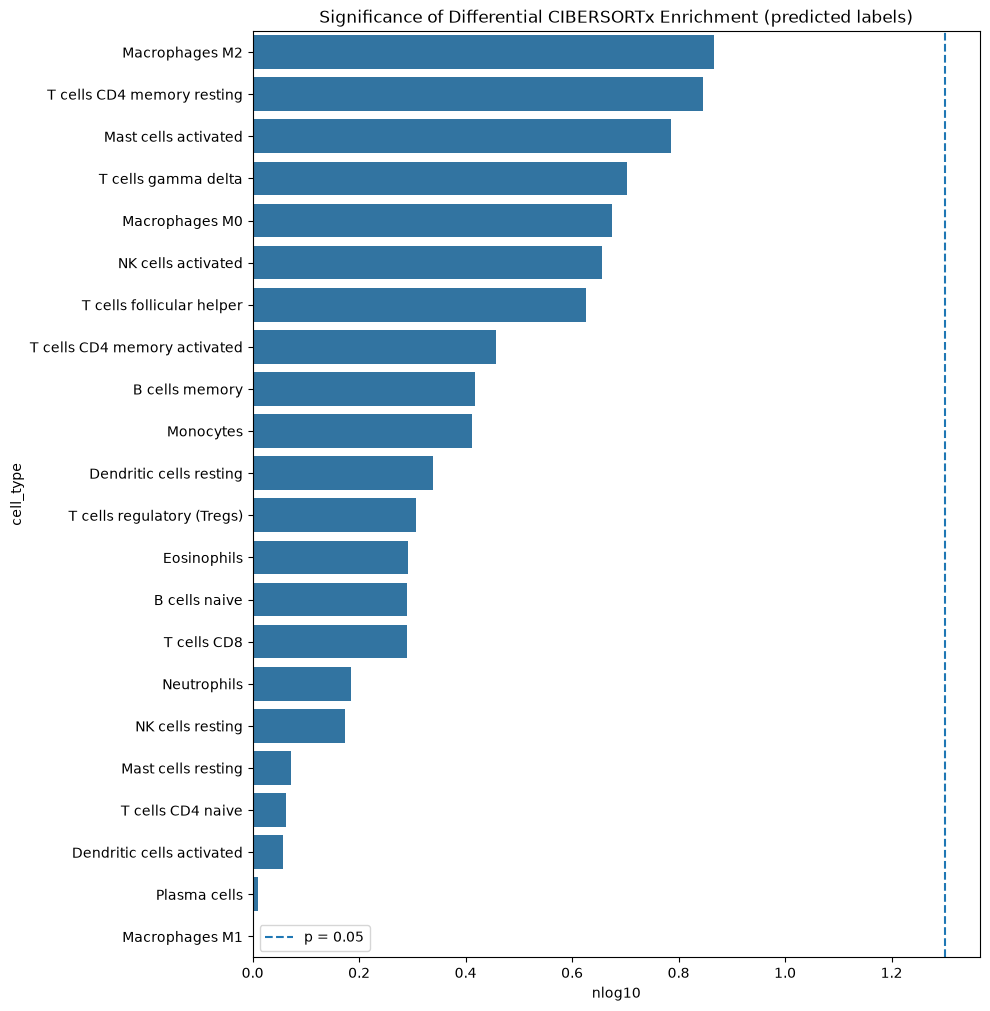

In [326]:
fig, ax = plt.subplots(1, figsize=(10,10))
sns.barplot(res_df.sort_values(by='nlog10', ascending=False), x='nlog10', y='cell_type')

plt.tight_layout()
plt.title("Significance of Differential CIBERSORTx Enrichment (predicted labels)")

ax.axvline(-np.log10(0.05), ls='--', label='p = 0.05')
#ax.tick_params("x", rotation=90, rotation_mode="xtick")
plt.legend()

#### Pearson correlation (enrichment to AUC and to predicted probability) - show heatmap

In [140]:
auc_correlation_results = {}

for cell_type in cell_types:
    auc_correlation_results[cell_type] = {'Correlation w/ veneotclax response (AUC)': pearsonr(cibersort_results_ml[cell_type], cibersort_results_ml['ABT-199']).statistic}
                                      #'y_prob':  pearsonr(cibersort_results_ml[cell_type], cibersort_results_ml['y_prob']).statistic}

auc_correlation_results = pd.DataFrame(auc_correlation_results).T
auc_correlation_results['cell_type'] = auc_correlation_results.index
auc_correlation_results['direction'] = auc_correlation_results['Correlation w/ veneotclax response (AUC)' ] > 0
auc_correlation_results['direction'] = ['Up' if v == True else 'Down' for v in auc_correlation_results['direction']]

/tmp/ipykernel_40097/1095008574.py:4: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  auc_correlation_results[cell_type] = {'Correlation w/ veneotclax response (AUC)': pearsonr(cibersort_results_ml[cell_type], cibersort_results_ml['ABT-199']).statistic}


<Axes: xlabel='Correlation w/ veneotclax response (AUC)', ylabel='cell_type'>

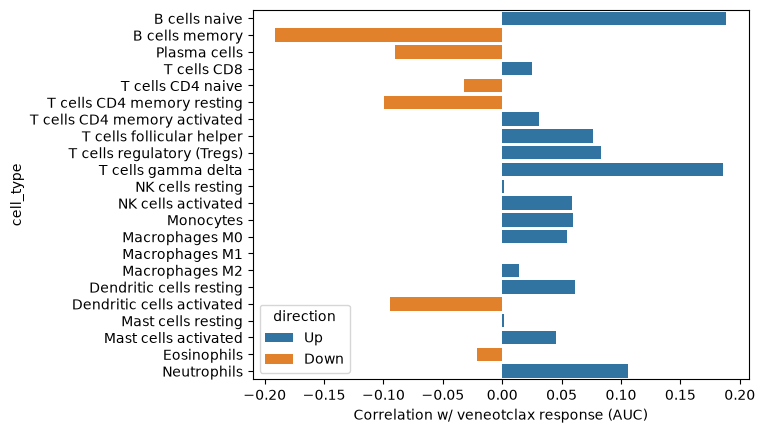

In [141]:
sns.barplot(auc_correlation_results, y='cell_type', x='Correlation w/ veneotclax response (AUC)', hue='direction')

/tmp/ipykernel_40097/2698864173.py:4: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  y_prob_correlation_results[cell_type] = {'Correlation w/ predicted probability of venetoclax response': pearsonr(cibersort_results_ml[cell_type], cibersort_results_ml['y_prob']).statistic}


<Axes: xlabel='Correlation w/ predicted probability of venetoclax response', ylabel='cell_type'>

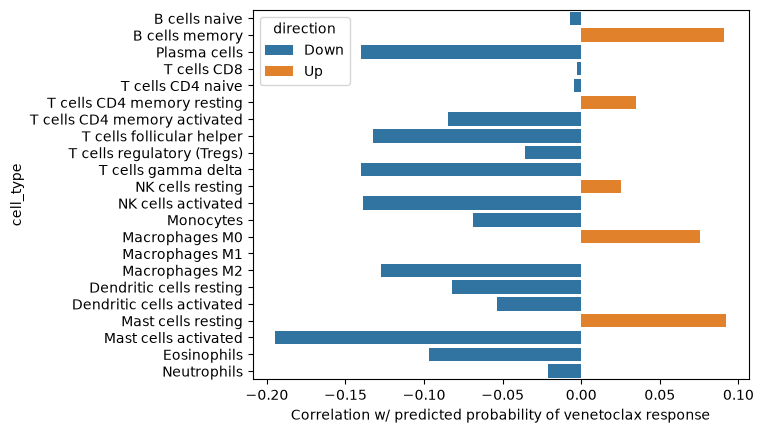

In [142]:
y_prob_correlation_results = {}

for cell_type in cell_types:
    y_prob_correlation_results[cell_type] = {'Correlation w/ predicted probability of venetoclax response': pearsonr(cibersort_results_ml[cell_type], cibersort_results_ml['y_prob']).statistic}
                                      #'y_prob':  pearsonr(cibersort_results_ml[cell_type], cibersort_results_ml['y_prob']).statistic}

y_prob_correlation_results = pd.DataFrame(y_prob_correlation_results).T
y_prob_correlation_results['cell_type'] = y_prob_correlation_results.index
y_prob_correlation_results['direction'] = y_prob_correlation_results['Correlation w/ predicted probability of venetoclax response' ] > 0
y_prob_correlation_results['direction'] = ['Up' if v == True else 'Down' for v in y_prob_correlation_results['direction']]

sns.barplot(y_prob_correlation_results, y='cell_type', x='Correlation w/ predicted probability of venetoclax response', hue='direction')

#### Correlation of gupta 6-gene signature with cibersort

In [154]:
Gupta_six_gene_signature =  ['VPREB3', 'CCR7', 'SORL1', 'TRABD2A', 'EFEMP1', 'TDO2']

expr_df = mf_ad.to_df()

expr_correlation = {
    'VPREB3':[], 
    'CCR7':[], 
    'SORL1':[], 
    'TRABD2A':[], 
    'EFEMP1':[], 
    'TDO2':[]
}

for gene in Gupta_six_gene_signature:
    for cell_type in cell_types:
        expr_correlation[gene].append(pearsonr(expr_df[gene], cibersort_results_ml[cell_type]).statistic)
        
expr_correlation = pd.DataFrame(expr_correlation, index=cell_types)

/tmp/ipykernel_40097/1922448998.py:16: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  expr_correlation[gene].append(pearsonr(expr_df[gene], cibersort_results_ml[cell_type]).statistic)


Text(0.5, 1.0, 'Correlation of cell type to Gupta et al. six-gene signature')

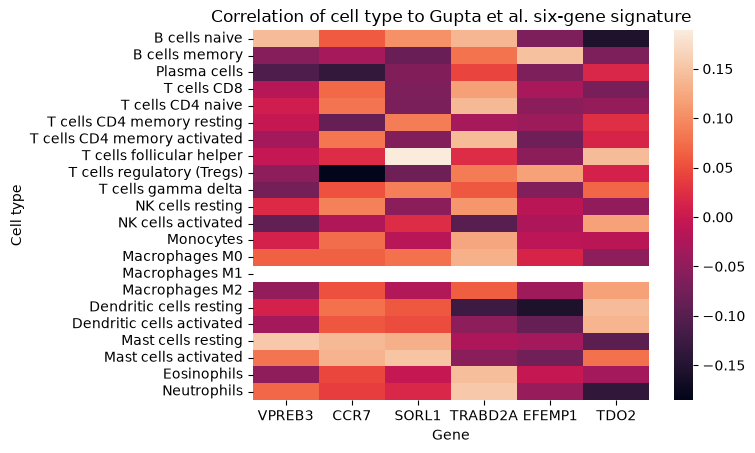

In [160]:
fig, ax = plt.subplots(1)
sns.heatmap(expr_correlation)
ax.set_xlabel("Gene")
ax.set_ylabel("Cell type")
ax.set_title("Correlation of cell type to Gupta et al. six-gene signature")


In [258]:
comparing_features_results = pd.read_csv("../../outputs/comparing_published_genesets.csv").set_index("Unnamed: 0")
comparing_features_results.index.name = 'Model'

comparing_features_results_std = pd.read_csv("../../outputs/comparing_published_genesets_with_variability.csv").set_index("Unnamed: 0")
comparing_features_results_std.index.name = 'Model'


In [270]:
comparing_features_results

,Gupta_six_gene_signature,BCL2_family_ratios,Leblay_integrated_single_cell,BCL2_family_ratios + Gupta_six_gene_signature,t11_14_degs,SHAFFER_IRF4_TARGETS_IN_MYELOMA_VS_MATURE_B_LYMPHOCYTE.v2026.2.Hs.gmt,chr1p12.v2026.2.Hs.gmt,chr11q13.v2026.2.Hs.gmt,chr11q12.v2026.2.Hs.gmt,HANN_RESISTANCE_TO_BCL2_INHIBITOR_UP.v2026.2.Hs.gmt,...,chr11q14.v2026.2.Hs.gmt,TARTE_PLASMA_CELL_VS_B_LYMPHOCYTE_DN.v2026.2.Hs.gmt,ZHAN_LATE_DIFFERENTIATION_GENES_UP.v2026.2.Hs.gmt,SHAFFER_IRF4_TARGETS_IN_ACTIVATED_DENDRITIC_CELL.v2026.2.Hs.gmt,TARTE_PLASMA_CELL_VS_B_LYMPHOCYTE_UP.v2026.2.Hs.gmt,SHAFFER_IRF4_MULTIPLE_MYELOMA_PROGRAM.v2026.2.Hs.gmt,ZHAN_MULTIPLE_MYELOMA_DN.v2026.2.Hs.gmt,chr11q21.v2026.2.Hs.gmt,KEGG_MEDICUS_VARIANT_BCL2_OVEREXPRESSION_TO_INTRINSIC_APOPTOTIC_PATHWAY.v2026.2.Hs.gmt,all
Model,,,,,,,,,,,,,,,,,,,,,
RidgeClassifier,0.733074,0.682753,0.607509,0.708898,0.669063,0.392720,0.522665,0.579197,0.527885,0.527640,...,0.532387,0.462790,0.701084,0.541041,0.498046,0.363813,0.367109,0.408288,0.608578,0.581853
LogisticRegression,0.725855,0.679335,0.597634,0.723214,0.661813,0.437469,0.502976,0.591804,0.527534,0.517323,...,0.546612,0.444261,0.663874,0.532357,0.585394,0.357250,0.367201,0.401587,0.598611,0.569994
SGDClassifier,0.553816,0.532998,0.677457,0.641331,0.675473,0.483028,0.418452,0.553053,0.493010,0.506074,...,0.540934,0.435882,0.660806,0.587943,0.559127,0.368849,0.368712,0.438904,0.562347,0.526297
GaussianNB,0.709509,0.685882,0.646230,0.737698,0.571680,0.369353,0.302793,0.533410,0.516774,0.479502,...,0.520437,0.538904,0.540018,0.371703,0.413004,0.418590,0.534142,0.375626,0.426938,0.484417
RandomForestClassifier,0.700259,0.676664,0.601946,0.697237,0.646215,0.440591,0.519383,0.533868,0.474443,0.434875,...,0.423230,0.490514,0.533097,0.465789,0.572894,0.502961,0.490850,0.411836,0.540171,0.489362
LinearSVC,0.724145,0.675763,0.599573,0.703770,0.661859,0.465965,0.534768,0.583532,0.518407,0.514789,...,0.528404,0.468346,0.665385,0.536981,0.547405,0.387103,0.352961,0.414621,0.606716,0.578694
SVC,0.710226,0.635516,0.555037,0.692170,0.630479,0.460302,0.574786,0.534692,0.511432,0.379457,...,0.513233,0.538187,0.555281,0.469872,0.574466,0.454487,0.407937,0.375015,0.541545,0.495604
HistGradientBoostingClassifier,0.705968,0.620566,0.551664,0.673390,0.605372,0.418071,0.465621,0.412332,0.547833,0.495360,...,0.397161,0.459509,0.444399,0.374435,0.589423,0.436493,0.424756,0.530449,0.564072,0.508318


In [319]:
median_df = pd.DataFrame({'Median ROC-AUC across models': comparing_features_results.median(), 'feature_set': comparing_features_results.columns})

In [320]:
median_df

,Median ROC-AUC across models,feature_set
Gupta_six_gene_signature,0.709867,Gupta_six_gene_signature
BCL2_family_ratios,0.676213,BCL2_family_ratios
Leblay_integrated_single_cell,0.600759,Leblay_integrated_single_cell
BCL2_family_ratios + Gupta_six_gene_signature,0.700504,BCL2_family_ratios + Gupta_six_gene_signature
t11_14_degs,0.654014,t11_14_degs
SHAFFER_IRF4_TARGETS_IN_MYELOMA_VS_MATURE_B_LYMPHOCYTE.v2026.2.Hs.gmt,0.439030,SHAFFER_IRF4_TARGETS_IN_MYELOMA_VS_MATURE_B_LY...
chr1p12.v2026.2.Hs.gmt,0.511180,chr1p12.v2026.2.Hs.gmt
chr11q13.v2026.2.Hs.gmt,0.543872,chr11q13.v2026.2.Hs.gmt
chr11q12.v2026.2.Hs.gmt,0.517590,chr11q12.v2026.2.Hs.gmt
HANN_RESISTANCE_TO_BCL2_INHIBITOR_UP.v2026.2.Hs.gmt,0.500717,HANN_RESISTANCE_TO_BCL2_INHIBITOR_UP.v2026.2.H...


/tmp/ipykernel_40097/58278165.py:4: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


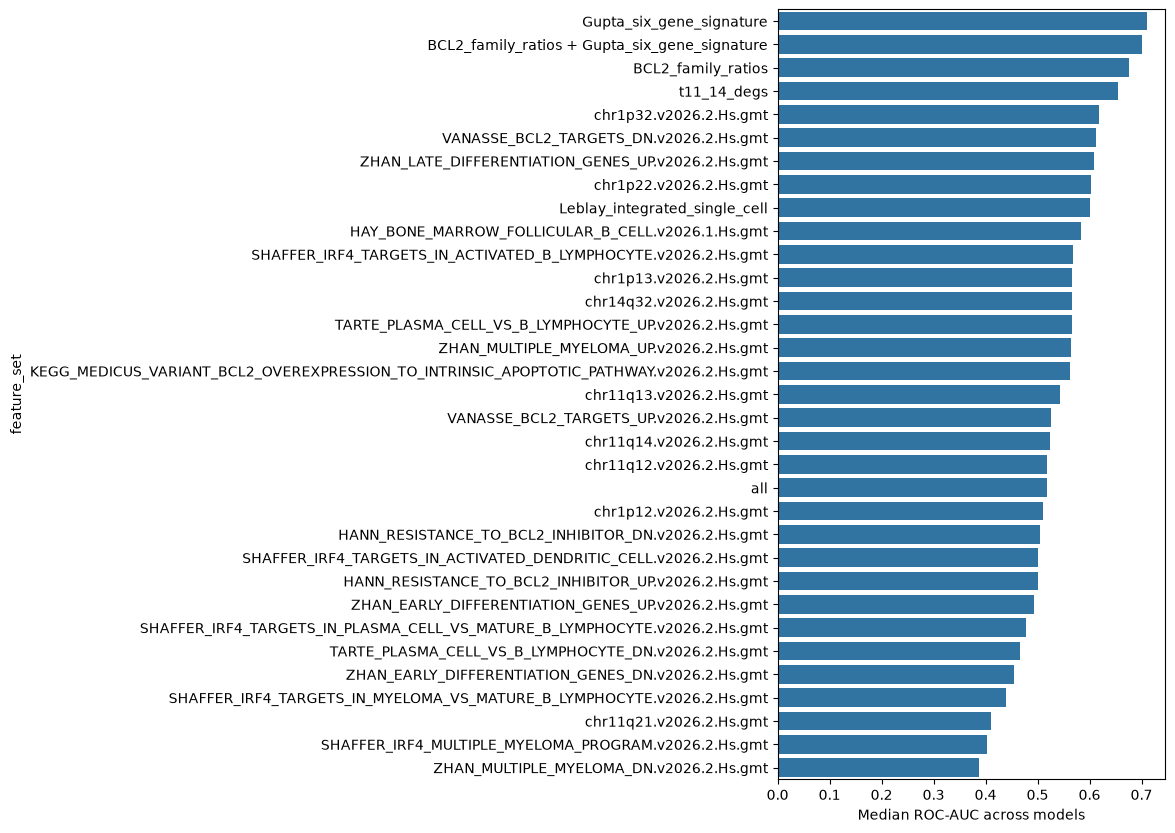

In [ ]:
fig, ax = plt.subplots(1, figsize=(5,10))
sns.barplot(median_df.sort_values(by='Median ROC-AUC across models', ascending=False), x='Median ROC-AUC across models', y='feature_set') # show after horizontal line plots

fig.tight_layout()

In [259]:
for col in comparing_features_results_std.columns:
    comparing_features_results_std[col] = comparing_features_results_std[col].str[12:]

In [262]:
comparing_features_results_std = comparing_features_results_std.astype(float)

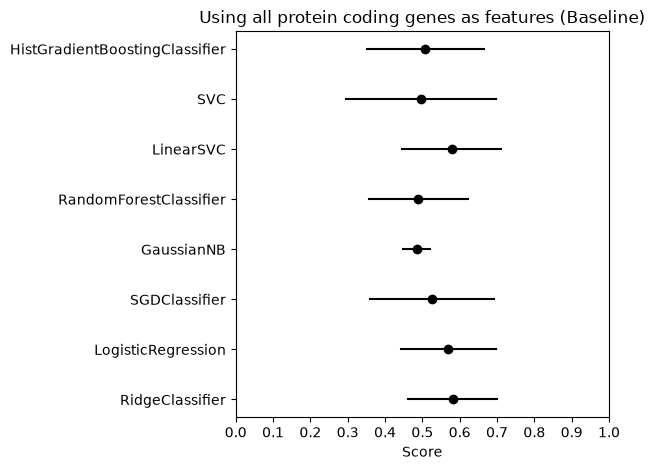

In [284]:
roc_auc_gupta = comparing_features_results['all']
roc_auc_gupta_std = comparing_features_results_std['all']

for i, model in enumerate(roc_auc_gupta.index):
    plt.plot([roc_auc_gupta.loc[model] - roc_auc_gupta_std[model], roc_auc_gupta.loc[model] + roc_auc_gupta_std[model]], [i + 1, i+1], c='k')
    plt.plot(roc_auc_gupta.loc[model],i+1, marker='o', c='k')

plt.yticks(np.arange(len(roc_auc_gupta.index)) + 1, list(roc_auc_gupta.index))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.xlabel('Score')
plt.title("Using all protein coding genes as features (Baseline)")
plt.tight_layout()

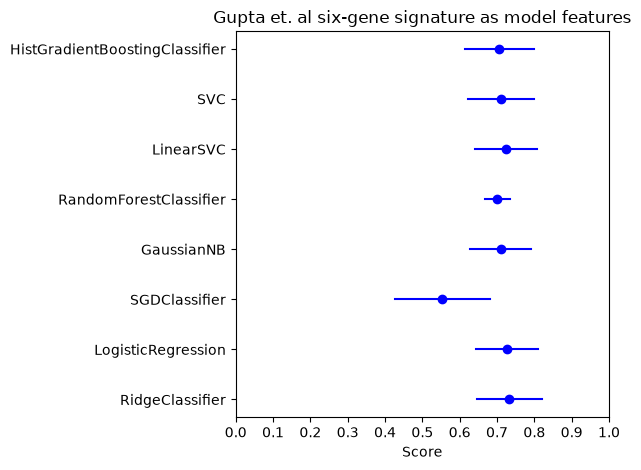

In [280]:
roc_auc_gupta = comparing_features_results['Gupta_six_gene_signature']
roc_auc_gupta_std = comparing_features_results_std['Gupta_six_gene_signature']

for i, model in enumerate(roc_auc_gupta.index):
    plt.plot([roc_auc_gupta.loc[model] - roc_auc_gupta_std[model], roc_auc_gupta.loc[model] + roc_auc_gupta_std[model]], [i + 1, i+1], c='blue')
    plt.plot(roc_auc_gupta.loc[model],i+1, marker='o', c='blue')

plt.yticks(np.arange(len(roc_auc_gupta.index)) + 1, list(roc_auc_gupta.index))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.xlabel('Score')
plt.title("Gupta et. al six-gene signature as model features")
plt.tight_layout()




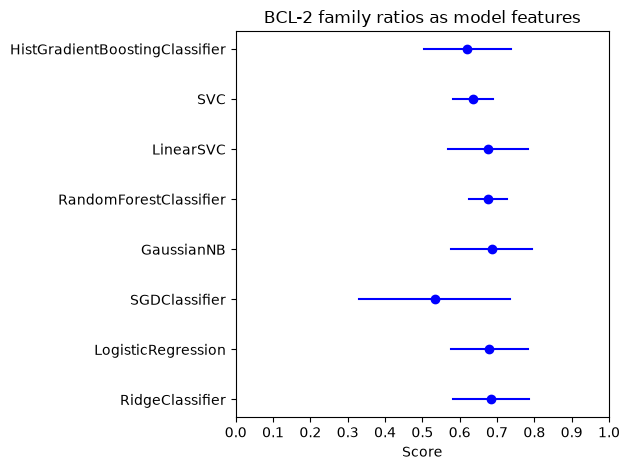

In [281]:
roc_auc = comparing_features_results['BCL2_family_ratios']
roc_auc_std = comparing_features_results_std['BCL2_family_ratios']

for i, model in enumerate(roc_auc.index):
    plt.plot([roc_auc.loc[model] - roc_auc_std[model], roc_auc.loc[model] + roc_auc_std[model]], [i + 1, i+1], c='blue')
    plt.plot(roc_auc.loc[model],i+1, marker='o', c='blue')

plt.yticks(np.arange(len(roc_auc.index)) + 1, list(roc_auc.index))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.xlabel('Score')
plt.title("BCL-2 family ratios as model features")
plt.tight_layout()


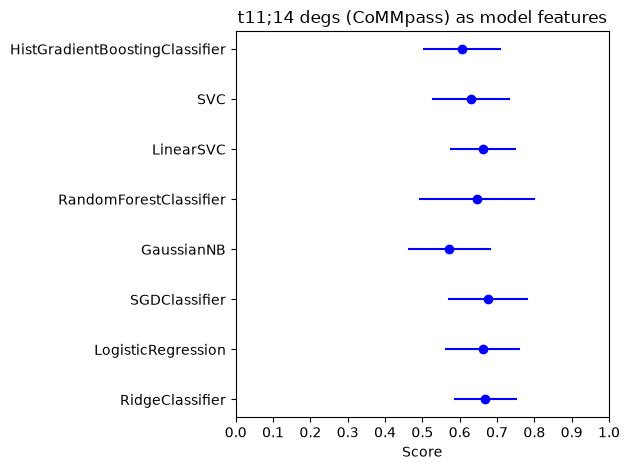

In [282]:
roc_auc = comparing_features_results['t11_14_degs']
roc_auc_std = comparing_features_results_std['t11_14_degs']

for i, model in enumerate(roc_auc.index):
    plt.plot([roc_auc.loc[model] - roc_auc_std[model], roc_auc.loc[model] + roc_auc_std[model]], [i + 1, i+1], c='blue')
    plt.plot(roc_auc.loc[model],i+1, marker='o', c='blue')

plt.yticks(np.arange(len(roc_auc.index)) + 1, list(roc_auc.index))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.xlabel('Score')
plt.title("t11;14 degs (CoMMpass) as model features")
plt.tight_layout()

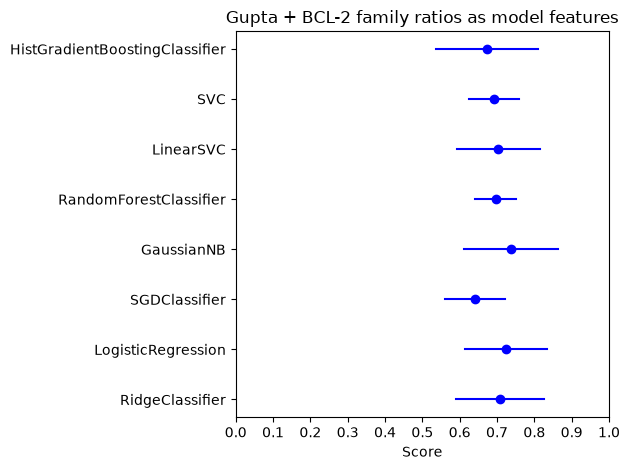

In [283]:
roc_auc = comparing_features_results['BCL2_family_ratios + Gupta_six_gene_signature']
roc_auc_std = comparing_features_results_std['BCL2_family_ratios + Gupta_six_gene_signature']

for i, model in enumerate(roc_auc.index):
    plt.plot([roc_auc.loc[model] - roc_auc_std[model], roc_auc.loc[model] + roc_auc_std[model]], [i + 1, i+1], c='blue')
    plt.plot(roc_auc.loc[model],i+1, marker='o', c='blue')

plt.yticks(np.arange(len(roc_auc.index)) + 1, list(roc_auc.index))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.xlabel('Score')
plt.title("Gupta + BCL-2 family ratios as model features")
plt.tight_layout()